In [2]:
from datetime import datetime
from rqrisk import Risk
from dateutil.relativedelta import relativedelta
from rqdatac.validators import ensure_date_range
import matplotlib.pyplot as plt
import rqdatac
from scipy import stats
rqdatac.init()

/home/windsoilder/projects/quant_study/.venv/lib/python3.14/site-packages/rqdatac/client.py:224: UserWarning: rqdatac is already inited. Settings will be changed.
  warnings.warn("rqdatac is already inited. Settings will be changed.", stacklevel=0)


In [3]:
def show_max_drawdown(order_book_id, start_date, end_date):
    start_date, end_date = ensure_date_range(None, None, delta=relativedelta(years=10))
    prices = rqdatac.get_price(order_book_id, start_date, end_date, fields=["close"])["close"]
    prices.reset_index("order_book_id", inplace=True, drop=True)
    hist_high = prices.cummax()
    drawdown = 1 - prices / hist_high
    maxdd_low = drawdown.idxmax()
    maxdd_high = prices[prices.index < maxdd_low].idxmax()
    

    plt.figure()
    plt.plot(prices)
    plt.plot(maxdd_high, prices[maxdd_high], marker='o', c='red')
    plt.plot(maxdd_low, prices[maxdd_low], marker='o', c='red')
    plt.show()

/tmp/ipykernel_398/3035228365.py:4: Pandas4Warning: The inplace keyword in Series.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  prices.reset_index("order_book_id", inplace=True, drop=True)


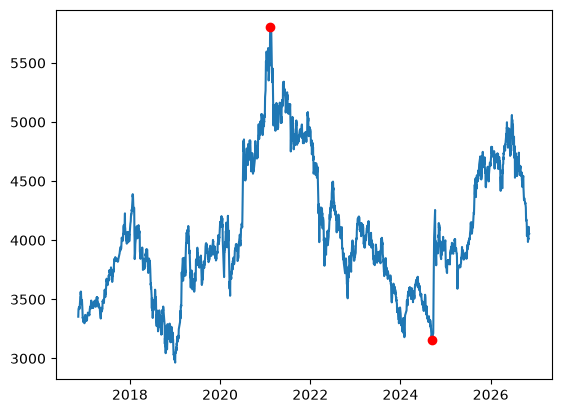

In [16]:
show_max_drawdown("000300.XSHG", None, None)

In [29]:
def show_ma(order_book_id, start_date, end_date):
    start_date, end_date = ensure_date_range(None, None, delta=relativedelta(years=10))
    df = rqdatac.get_price(order_book_id, start_date, end_date, fields=["close"])["close"]
    df.reset_index("order_book_id", drop=True, inplace=True)
    ma_60 = df.rolling(window=60).mean()
    plt.figure()
    plt.plot(df)
    plt.plot(ma_60)
    plt.legend(["ma60"])
    plt.show()

/tmp/ipykernel_398/3000335502.py:4: Pandas4Warning: The inplace keyword in Series.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index("order_book_id", drop=True, inplace=True)


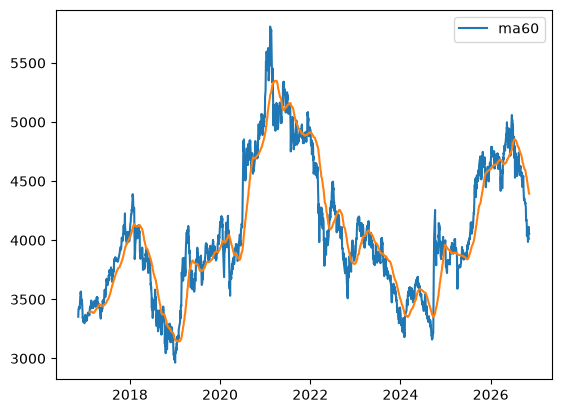

In [30]:
show_ma("000300.XSHG", None, None)

In [31]:
df.ewm?

Signature:
df.ewm(
    com: 'float | None' = None,
    span: 'float | None' = None,
    halflife: 'float | TimedeltaConvertibleTypes | None' = None,
    alpha: 'float | None' = None,
    min_periods: 'int | None' = 0,
    adjust: 'bool' = True,
    ignore_na: 'bool' = False,
    times: 'np.ndarray | DataFrame | Series | None' = None,
    method: "Literal['single', 'table']" = 'single',
) -> 'ExponentialMovingWindow'
Docstring:
Provide exponentially weighted (EW) calculations.

Exactly one of ``com``, ``span``, ``halflife``, or ``alpha`` must be
provided if ``times`` is not provided. If ``times`` is provided and
``adjust=True``, ``halflife`` and one of ``com``, ``span`` or ``alpha``
may be provided.
If ``times`` is provided and ``adjust=False``, ``halflife``
must be the only provided decay-specification parameter.

Parameters
----------
com : float, optional
    Specify decay in terms of center of mass

    :math:`\alpha = 1 / (1 + com)`, for :math:`com \geq 0`.

span : float, optional


In [12]:
(4702.0247 + 4663.7887) / 2

4682.9067

In [ ]:
import rqdatac
rqdatac.init()
import matplotlib as plt

df = rqdatac.get_price("000300.XSHG", start_date, end